# Ice Cream Revenue Prediction

**Project area:** Machine Learning  
**Algorithm:** Simple Linear Regression  
**Student name:** Krishna Kumar Mallik

## Aim
The aim of this project is to check whether temperature can help predict ice cream sales revenue. I will prepare a small dataset, train a regression model, test it, and try a prediction for a new temperature.

This is a beginner-friendly learning version inspired by the `Icecream_Revenue_Prediction.ipynb` project in the YBI Foundation Internship repository. The sample data below is included in the notebook so it can run without downloading a separate file.

## 1. Import the libraries
I use pandas to work with the data, matplotlib to make a graph, and scikit-learn to train and evaluate the model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

## 2. Create and inspect the dataset
For this demonstration, the table contains example temperatures and revenue values. Revenue is measured in the dataset's example units; it is not real business data.

In [2]:
data = {
    "Temperature": [14, 16, 18, 20, 22, 24, 26, 28, 30, 32,
                    15, 19, 21, 23, 25, 27, 29, 31, 17, 33],
    "Revenue": [120, 135, 160, 180, 205, 230, 255, 280, 310, 335,
                125, 170, 195, 215, 245, 265, 295, 325, 145, 350]
}
df = pd.DataFrame(data)

display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nSummary:")
display(df.describe())

,Temperature,Revenue
0,14,120
1,16,135
2,18,160
3,20,180
4,22,205


Dataset shape: (20, 2)

Missing values:
Temperature    0
Revenue        0
dtype: int64

Summary:


,Temperature,Revenue
count,20.00000,20.000000
mean,23.50000,227.000000
std,5.91608,73.240771
min,14.00000,120.000000
25%,18.75000,167.500000
50%,23.50000,222.500000
75%,28.25000,283.750000
max,33.00000,350.000000


## 3. Explore the relationship
The scatter plot helps us see whether revenue tends to rise as temperature rises.

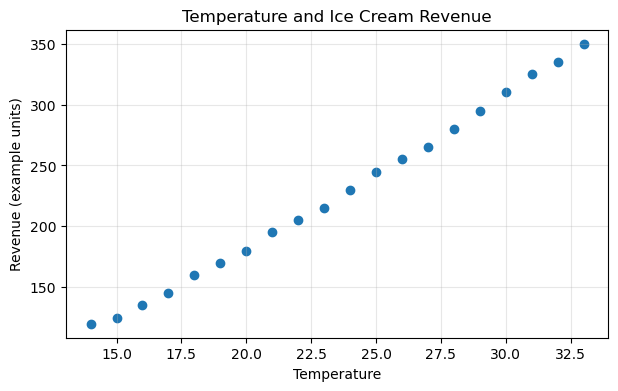

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(df["Temperature"], df["Revenue"])
plt.xlabel("Temperature")
plt.ylabel("Revenue (example units)")
plt.title("Temperature and Ice Cream Revenue")
plt.grid(True, alpha=0.3)
plt.show()

## 4. Prepare training and testing data
Temperature is the input feature (`X`) and revenue is the value we want to predict (`y`). I keep some rows aside to test the model on data it did not train on.

In [4]:
X = df[["Temperature"]]
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 15
Testing rows: 5


## 5. Train the model
Linear regression fits a straight line through the training examples.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 2))
print("Temperature coefficient:", round(model.coef_[0], 2))

## 6. Evaluate the model
Mean Absolute Error (MAE) shows the average size of the prediction error. The R² score describes how well the model explains variation in this test set. Results can change if the dataset changes.

In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual revenue": y_test.values,
    "Predicted revenue": y_pred.round(2)
})
display(results)

print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("R² score:", round(r2_score(y_test, y_pred), 3))

## 7. Plot the fitted line
The line shows the predictions made by the trained model across the temperature range in this sample.

In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(X["Temperature"], y, label="Sample data")
plt.plot(X["Temperature"], model.predict(X), label="Regression line")
plt.xlabel("Temperature")
plt.ylabel("Revenue (example units)")
plt.title("Linear Regression: Revenue Prediction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 8. Predict revenue for a new temperature
Change the temperature value below and run this cell again to try your own example.

In [ ]:
new_temperature = 27
new_data = pd.DataFrame({"Temperature": [new_temperature]})
predicted_revenue = model.predict(new_data)[0]

print(f"At temperature {new_temperature}, predicted revenue is "
      f"{predicted_revenue:.2f} example units.")

## 9. Conclusion

- In this sample dataset, revenue generally increases as temperature increases.
- Linear regression gives a simple baseline for predicting revenue from one input.
- The MAE and R² score help evaluate predictions on the test rows.
- The dataset is small and illustrative, so the results should not be treated as a real sales forecast.
- Other factors such as season, location, price, and promotions could also affect actual revenue.

## 10. What I would improve next
1. Replace the example values with a real dataset and cite its source.
2. Compare predictions with a second model.
3. Try more input features if reliable data is available.